In [1]:
%matplotlib inline

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sns.set(style="darkgrid")

In [4]:
df = pd.read_csv('Vehiculos.csv', encoding='latin1', sep=';')

In [5]:
df.columns

Index(['Fabricante', 'Modelo', 'Ventas en miles', 'Valor de reventa a 4 aos',
       'Tipo de vehculo', 'Precio en miles', 'Tamao del motor', 'Caballos',
       'Base de neumticos', 'Anchura', 'Longitud', 'Peso neto',
       'Capacidad de combustible', 'Consumo'],
      dtype='str')

In [6]:
# Convertir a numèric netejant possibles caràcters especials
df['Precio en miles'] = pd.to_numeric(df['Precio en miles'].astype(str).str.replace(',', '.'), errors='coerce')
df['Caballos'] = pd.to_numeric(df['Caballos'].astype(str).str.replace(',', '.'), errors='coerce')

# Crear la nova columna de Preu per cada Cavall de potència (Precio en miles * 1000 / Caballos) o ràtio similar
# O en milers de dòlars per cavall:
df['Precio_Potencia'] = (df['Precio en miles'] * 1000 / df['Caballos']).round(2)

In [7]:
pd.set_option('display.max_rows', None)
df[['Fabricante', 'Modelo', 'Precio en miles', 'Caballos', 'Precio_Potencia']].dropna().drop_duplicates()

,Fabricante,Modelo,Precio en miles,Caballos,Precio_Potencia
0,Acura,Integra,21.500,140.0,153.57
1,Acura,TL,28.400,225.0,126.22
3,Acura,RL,42.000,210.0,200.00
4,Audi,A4,23.990,150.0,159.93
5,Audi,A6,33.950,200.0,169.75
6,Audi,A8,62.000,310.0,200.00
7,BMW,323i,26.990,170.0,158.76
8,BMW,328i,33.400,193.0,173.06
9,BMW,528i,38.900,193.0,201.55
10,Buick,Century,21.975,175.0,125.57


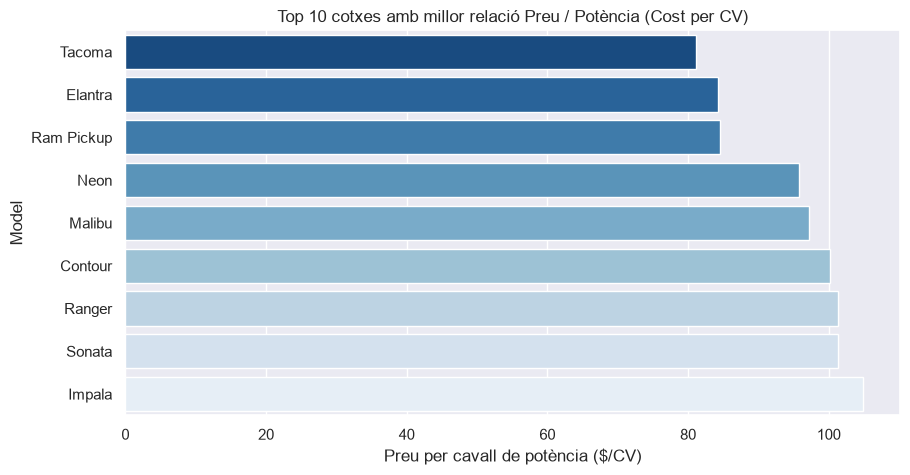

In [8]:
# Ordenar de menor a major ràtio preu/potència (o els més econòmics per cavall) i agafar els 10 primers
top10_precio_potencia = df.sort_values('Precio_Potencia').dropna(subset=['Precio_Potencia']).head(10)

# Gràfic de barres
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top10_precio_potencia, 
    x='Precio_Potencia', 
    y='Modelo', 
    hue='Modelo', 
    palette='Blues_r', 
    legend=False
)

plt.title('Top 10 cotxes amb millor relació Preu / Potència (Cost per CV)')
plt.xlabel('Preu per cavall de potència ($/CV)')
plt.ylabel('Model')
plt.show()